# P11 – FC 24 Position Finder ⚽
### Forward, midfielder or defender? Let the player ratings decide.

| | |
|---|---|
| **Project** | P11 – FC 24 Position Finder (Sports) |
| **Name** | KANARA JATIN JIJI |
| **Roll No.** | F10 |
| **Enrollment No.** | 24004501210126 |
| **Division** | E |
| **Model** | Random Forest (only) |
| **Main metric** | Macro F1 |

> **Evaluation note (important):** `train.py` is the canonical, leakage-safe training pipeline for the delivered app. It splits before supervised feature selection, performs fold-specific imputation and feature selection inside 3-fold stratified cross-validation, selects the model by training CV macro F1, and reports final metrics on an untouched held-out test split. Use `python train.py` for the current verified results. Earlier exploratory notebook cells are retained for teaching/EDA and should not be used as the final source of reported metrics unless rerun with the corrected pipeline.


## Step 1: Create the notebook and load the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay)
from sklearn.ensemble import RandomForestClassifier
import warnings; warnings.filterwarnings("ignore")
print("All libraries loaded!")

All libraries loaded!


✍️ **Write in your notebook:** This is project **P11 – FC 24 Position Finder** (Div E). All libraries loaded without errors ("All libraries loaded!"), so the notebook is ready. Name, roll no. and enrollment no. are in the title cell at the top.

## Step 2: Load the dataset

In [2]:
# Option A (used here): male_players.csv downloaded from Kaggle and uploaded to Colab / put in the same folder.
#   The GitHub repo also ships data/fc24_players.csv = the 18,350 FC 24 rows of that same Kaggle file.
#   In Colab you can fetch it with:  !wget -q https://raw.githubusercontent.com/USERNAME/REPO/main/data/fc24_players.csv
# Option B (kagglehub):
#   import kagglehub, os
#   path = kagglehub.dataset_download("stefanoleone992/ea-sports-fc-24-complete-player-dataset")
#   df = pd.read_csv(os.path.join(path, "male_players.csv"), low_memory=False)
import os
for path in ["male_players.csv", "data/male_players.csv", "fc24_players.csv", "data/fc24_players.csv"]:
    if os.path.exists(path):
        break
df = pd.read_csv(path, low_memory=False)
df = df[df["fifa_version"] == 24]      # keep only FC 24 players
print(path, df.shape)
df.head()

data/fc24_players.csv (18350, 109)


,player_id,player_url,fifa_version,fifa_update,update_as_of,short_name,long_name,player_positions,overall,potential,...,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk
0,231747,/player/231747/kylian-mbappe/240002,24.0,2.0,2023-09-22,K. Mbappé,Kylian Mbappé Lottin,"ST, LW",91,94,...,63+3,63+3,63+3,68+3,63+3,54+3,54+3,54+3,63+3,18+3
1,239085,/player/239085/erling-haaland/240002,24.0,2.0,2023-09-22,E. Haaland,Erling Braut Haaland,ST,91,94,...,63+3,63+3,63+3,62+3,60+3,62+3,62+3,62+3,60+3,19+3
2,192985,/player/192985/kevin-de-bruyne/240002,24.0,2.0,2023-09-22,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,...,80+3,80+3,80+3,79+3,75+3,70+3,70+3,70+3,75+3,21+3
3,158023,/player/158023/lionel-messi/240002,24.0,2.0,2023-09-22,L. Messi,Lionel Andrés Messi Cuccittini,"CF, CAM",90,90,...,63+3,63+3,63+3,64+3,59+3,49+3,49+3,49+3,59+3,19+3
4,165153,/player/165153/karim-benzema/240002,24.0,2.0,2023-09-22,K. Benzema,Karim Benzema,"CF, ST",90,90,...,64+3,64+3,64+3,64+3,60+3,55+3,55+3,55+3,60+3,18+3


✍️ **Write in your notebook:** The full `male_players.csv` has 180,021 rows (every FIFA 15 – FC 24 version). After keeping only `fifa_version == 24` the dataset has **18,350 rows and 109 columns** (one row per FC 24 player).
Source: Kaggle, "EA Sports FC 24 complete player dataset": https://www.kaggle.com/datasets/stefanoleone992/ea-sports-fc-24-complete-player-dataset

## Step 3: Understand the data

In [3]:
df.info()                   # column names, types, non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 18350 entries, 0 to 18349
Columns: 109 entries, player_id to gk
dtypes: float64(20), int64(43), str(46)
memory usage: 20.0 MB


In [4]:
df.describe()               # min, max, mean of number columns

,player_id,fifa_version,fifa_update,overall,potential,value_eur,wage_eur,age,height_cm,weight_kg,...,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed
count,18350.000000,18350.0,18350.0,18350.000000,18350.000000,1.825000e+04,18263.000000,18350.000000,18350.000000,18350.000000,...,18350.000000,18350.000000,18350.000000,18350.000000,18350.000000,18350.000000,18350.000000,18350.000000,18350.000000,2045.000000
mean,242440.726322,24.0,2.0,65.817057,71.088065,2.837585e+06,8723.388819,25.267139,181.698747,75.210354,...,57.976240,46.666975,48.532534,46.336240,16.329373,16.124578,16.035095,16.168392,16.423815,35.253790
std,26741.238580,0.0,0.0,6.817917,6.220982,7.562794e+06,18707.237605,4.757756,6.869995,6.985703,...,12.137094,20.415339,21.046124,20.569969,17.572154,16.945031,16.699136,17.093683,17.880726,10.591029
min,18115.000000,24.0,2.0,47.000000,48.000000,1.000000e+04,500.000000,16.000000,156.000000,49.000000,...,13.000000,3.000000,8.000000,6.000000,2.000000,2.000000,2.000000,2.000000,2.000000,15.000000
25%,225442.000000,24.0,2.0,62.000000,67.000000,4.750000e+05,1000.000000,21.000000,177.000000,70.000000,...,51.000000,29.000000,29.000000,26.000000,8.000000,8.000000,8.000000,8.000000,8.000000,26.000000
50%,245467.500000,24.0,2.0,66.000000,71.000000,1.000000e+06,3000.000000,25.000000,182.000000,75.000000,...,59.000000,52.000000,56.000000,53.000000,11.000000,11.000000,11.000000,11.000000,11.000000,34.000000
75%,264169.500000,24.0,2.0,70.000000,75.000000,2.000000e+06,8000.000000,29.000000,187.000000,80.000000,...,66.000000,63.000000,65.000000,63.000000,14.000000,14.000000,14.000000,14.000000,14.000000,44.000000
max,278145.000000,24.0,2.0,91.000000,94.000000,1.850000e+08,350000.000000,43.000000,206.000000,105.000000,...,96.000000,91.000000,91.000000,90.000000,90.000000,90.000000,91.000000,90.000000,93.000000,65.000000


In [5]:
pd.set_option("display.max_rows", 120)
print(df.isnull().sum())    # missing values in each column
print("Duplicates:", df.duplicated().sum())

player_id                             0
player_url                            0
fifa_version                          0
fifa_update                           0
update_as_of                          0
short_name                            0
long_name                             0
player_positions                      0
overall                               0
potential                             0
value_eur                           100
wage_eur                             87
age                                   0
dob                                   0
height_cm                             0
weight_kg                             0
club_team_id                         87
club_name                            87
league_id                            87
league_name                          87
league_level                         87
club_position                        87
club_jersey_number                   87
club_loaned_from                  17170
club_joined_date                   1267


### Data dictionary (all 109 columns)

| # | Column | Meaning | Type | Keep / Drop |
|---|---|---|---|---|
| 1 | `player_id` | Unique ID of the player in the dataset | Number | Drop: ID / link, no football meaning |
| 2 | `player_url` | Link to the player's sofifa.com page | Text | Drop: ID / link, no football meaning |
| 3 | `fifa_version` | Game version (15 to 24); we keep 24 = FC 24 | Number | Drop: same value for every FC 24 row |
| 4 | `fifa_update` | Which data update of that version the row comes from | Number | Drop: same value for every FC 24 row |
| 5 | `update_as_of` | Date of that data update | Text | Drop: same value for every FC 24 row |
| 6 | `short_name` | Short display name, e.g. 'K. Mbappé' | Text | Drop: name / free text / date |
| 7 | `long_name` | Full name of the player | Text | Drop: name / free text / date |
| 8 | `player_positions` | All positions the player can play, comma-separated; the first one is the main position | Text | Used to make the target, then dropped |
| 9 | `overall` | Overall rating (0-100) at the player's main position | Number | Drop (leak risk): calculated with the main position's formula |
| 10 | `potential` | Highest overall rating the player is expected to reach | Number | Drop (leak risk): follows overall |
| 11 | `value_eur` | Market value in euros | Number | Drop: money or club info, not a player attribute |
| 12 | `wage_eur` | Weekly wage in euros | Number | Drop: money or club info, not a player attribute |
| 13 | `age` | Age in years | Number | Keep |
| 14 | `dob` | Date of birth | Text | Drop: name / free text / date |
| 15 | `height_cm` | Height in cm | Number | Keep |
| 16 | `weight_kg` | Weight in kg | Number | Keep |
| 17 | `club_team_id` | ID of the club | Number | Drop: ID / link, no football meaning |
| 18 | `club_name` | Club name | Text | Drop: name / free text / date |
| 19 | `league_id` | ID of the league | Number | Drop: ID / link, no football meaning |
| 20 | `league_name` | League name | Text | Drop: name / free text / date |
| 21 | `league_level` | Tier of the league (1 = top division) | Number | Drop: money or club info, not a player attribute |
| 22 | `club_position` | Position in the club's line-up (e.g. ST, CB, SUB, RES) | Text | Drop (leak): it is the position itself |
| 23 | `club_jersey_number` | Shirt number at the club | Number | Drop: money or club info, not a player attribute |
| 24 | `club_loaned_from` | Club the player is on loan from (empty if not on loan) | Text | Drop: name / free text / date |
| 25 | `club_joined_date` | Date the player joined the club | Text | Drop: name / free text / date |
| 26 | `club_contract_valid_until_year` | Year the club contract ends | Number | Drop: money or club info, not a player attribute |
| 27 | `nationality_id` | ID of the player's country | Number | Drop: ID / link, no football meaning |
| 28 | `nationality_name` | Player's country | Text | Drop: name / free text / date |
| 29 | `nation_team_id` | ID of the national team (only if selected) | Number | Drop: ID / link, no football meaning |
| 30 | `nation_position` | Position in the national-team line-up (only if selected) | Text | Drop (leak): it is the position itself |
| 31 | `nation_jersey_number` | Shirt number for the national team | Number | Drop: money or club info, not a player attribute |
| 32 | `preferred_foot` | Stronger foot: Left or Right | Text | Keep: text, one-hot encoded in Step 7 |
| 33 | `weak_foot` | Weak-foot skill, 1 to 5 stars | Number | Keep |
| 34 | `skill_moves` | Skill-move ability, 1 to 5 stars | Number | Keep |
| 35 | `international_reputation` | Worldwide fame, 1 to 5 stars | Number | Keep |
| 36 | `work_rate` | Attacking / defensive work rate, e.g. 'High/Medium' | Text | Keep: text, one-hot encoded in Step 7 |
| 37 | `body_type` | Body build, e.g. 'Lean (185+)', 'Normal (170-185)' | Text | Drop: text label; height and weight already describe the body |
| 38 | `real_face` | Whether the game has a real face scan (Yes/No) | Text | Drop: about game graphics, not ability |
| 39 | `release_clause_eur` | Release clause in euros | Number | Drop: money or club info, not a player attribute |
| 40 | `player_tags` | Special tags, e.g. '#Speedster' (mostly empty) | Text | Drop: name / free text / date |
| 41 | `player_traits` | Special traits, e.g. 'Long Shot Taker (AI)' | Text | Drop: name / free text / date |
| 42 | `pace` | Main stat: speed (from acceleration + sprint speed) | Number | Keep |
| 43 | `shooting` | Main stat: shooting quality | Number | Keep |
| 44 | `passing` | Main stat: passing quality | Number | Keep |
| 45 | `dribbling` | Main stat: ball control and dribbling | Number | Keep |
| 46 | `defending` | Main stat: tackling, marking and interceptions | Number | Keep |
| 47 | `physic` | Main stat: strength, stamina, aggression | Number | Keep |
| 48 | `attacking_crossing` | Accuracy of crosses into the box | Number | Keep |
| 49 | `attacking_finishing` | Ability to score from chances inside the box | Number | Keep |
| 50 | `attacking_heading_accuracy` | Accuracy of headers | Number | Keep |
| 51 | `attacking_short_passing` | Accuracy of short passes | Number | Keep |
| 52 | `attacking_volleys` | Striking the ball before it bounces | Number | Keep |
| 53 | `skill_dribbling` | Keeping the ball close while running | Number | Keep |
| 54 | `skill_curve` | Putting curve on the ball | Number | Keep |
| 55 | `skill_fk_accuracy` | Free-kick accuracy | Number | Keep |
| 56 | `skill_long_passing` | Accuracy of long passes | Number | Keep |
| 57 | `skill_ball_control` | First touch and control | Number | Keep |
| 58 | `movement_acceleration` | How quickly the player reaches top speed | Number | Keep |
| 59 | `movement_sprint_speed` | Top running speed | Number | Keep |
| 60 | `movement_agility` | Quick turns and changes of direction | Number | Keep |
| 61 | `movement_reactions` | How fast the player reacts to play | Number | Keep |
| 62 | `movement_balance` | Staying on feet under contact | Number | Keep |
| 63 | `power_shot_power` | Power of shots | Number | Keep |
| 64 | `power_jumping` | Jumping height | Number | Keep |
| 65 | `power_stamina` | Endurance over 90 minutes | Number | Keep |
| 66 | `power_strength` | Physical strength | Number | Keep |
| 67 | `power_long_shots` | Accuracy of shots from outside the box | Number | Keep |
| 68 | `mentality_aggression` | Willingness to tackle and challenge | Number | Keep |
| 69 | `mentality_interceptions` | Reading and cutting out passes | Number | Keep |
| 70 | `mentality_positioning` | Attacking runs and finding space | Number | Keep |
| 71 | `mentality_vision` | Seeing passing options | Number | Keep |
| 72 | `mentality_penalties` | Penalty-taking | Number | Keep |
| 73 | `mentality_composure` | Calmness under pressure | Number | Keep |
| 74 | `defending_marking_awareness` | Staying close to an opponent | Number | Keep |
| 75 | `defending_standing_tackle` | Winning the ball with standing tackles | Number | Keep |
| 76 | `defending_sliding_tackle` | Winning the ball with sliding tackles | Number | Keep |
| 77 | `goalkeeping_diving` | GK diving | Number | Keep |
| 78 | `goalkeeping_handling` | GK handling | Number | Keep |
| 79 | `goalkeeping_kicking` | GK kicking | Number | Keep |
| 80 | `goalkeeping_positioning` | GK positioning | Number | Keep |
| 81 | `goalkeeping_reflexes` | GK reflexes | Number | Keep |
| 82 | `goalkeeping_speed` | Goalkeeper speed (filled only for goalkeepers) | Number | Drop: empty for every outfield player |
| 83 | `ls` | The game's computed rating if the player played at LS, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 84 | `st` | The game's computed rating if the player played at ST, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 85 | `rs` | The game's computed rating if the player played at RS, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 86 | `lw` | The game's computed rating if the player played at LW, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 87 | `lf` | The game's computed rating if the player played at LF, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 88 | `cf` | The game's computed rating if the player played at CF, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 89 | `rf` | The game's computed rating if the player played at RF, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 90 | `rw` | The game's computed rating if the player played at RW, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 91 | `lam` | The game's computed rating if the player played at LAM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 92 | `cam` | The game's computed rating if the player played at CAM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 93 | `ram` | The game's computed rating if the player played at RAM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 94 | `lm` | The game's computed rating if the player played at LM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 95 | `lcm` | The game's computed rating if the player played at LCM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 96 | `cm` | The game's computed rating if the player played at CM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 97 | `rcm` | The game's computed rating if the player played at RCM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 98 | `rm` | The game's computed rating if the player played at RM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 99 | `lwb` | The game's computed rating if the player played at LWB, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 100 | `ldm` | The game's computed rating if the player played at LDM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 101 | `cdm` | The game's computed rating if the player played at CDM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 102 | `rdm` | The game's computed rating if the player played at RDM, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 103 | `rwb` | The game's computed rating if the player played at RWB, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 104 | `lb` | The game's computed rating if the player played at LB, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 105 | `lcb` | The game's computed rating if the player played at LCB, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 106 | `cb` | The game's computed rating if the player played at CB, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 107 | `rcb` | The game's computed rating if the player played at RCB, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 108 | `rb` | The game's computed rating if the player played at RB, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |
| 109 | `gk` | The game's computed rating if the player played at GK, e.g. '85+2' | Text | Drop (leak): rating at each position points to the answer |

✍️ **What I noticed:**
1. There are **no duplicate rows**, and the skill columns (crossing, finishing, tackling …) have no missing values. The 6 main stats (pace … physic) are empty only for the **2,045 goalkeepers**, who are removed in Step 4; the club/nation columns are mostly empty because most players are not in a national team.
2. Many columns are IDs, names, links or money, and **29 columns give away the position** (`club_position`, `nation_position` and the 27 position ratings like `st`, `cb`, `cm`), so they must be dropped to avoid leakage.

## Step 4: Prepare the target column (Y)

In [6]:
# Make 3 groups from the first position in player_positions
def group(pos):
    p = str(pos).split(",")[0].strip()
    if p in ["ST", "CF", "LW", "RW", "LF", "RF"]: return "FWD"
    if p in ["CM", "CDM", "CAM", "LM", "RM"]: return "MID"
    if p in ["CB", "LB", "RB", "LWB", "RWB"]: return "DEF"
    return None            # GK (goalkeepers) are removed
df["position_group"] = df["player_positions"].apply(group)
df = df.dropna(subset=["position_group"])
TARGET = "position_group"
print(df[TARGET].value_counts())
print((df[TARGET].value_counts(normalize=True) * 100).round(1))   # same counts as percentages

position_group
MID    6673
DEF    6174
FWD    3458
Name: count, dtype: int64
position_group
MID    40.9
DEF    37.9
FWD    21.2
Name: proportion, dtype: float64


✍️ **Write in your notebook:** The target has **3 classes: MID 6,673 (40.9%), DEF 6,174 (37.9%), FWD 3,458 (21.2%)** = 16,305 outfield players (2,045 goalkeepers removed).
The data is **imbalanced**: FWD is the minority class, about half the size of MID. So accuracy alone can hide mistakes on FWD, and **macro F1** (every class counts equally) is the metric we trust.

## Step 5: Clean the data

In [7]:
df = df.drop_duplicates()

# Drop ID / name / leaking columns (real column names from this data)
id_cols    = ["player_id", "player_url", "club_team_id", "league_id", "nationality_id", "nation_team_id"]
same_value = ["fifa_version", "fifa_update", "update_as_of"]          # the same for every FC 24 row
text_cols  = ["short_name", "long_name", "dob", "club_name", "league_name", "nationality_name",
              "club_loaned_from", "club_joined_date", "player_tags", "player_traits", "body_type", "real_face"]
not_skill  = ["value_eur", "wage_eur", "release_clause_eur", "league_level", "club_jersey_number",
              "nation_jersey_number", "club_contract_valid_until_year"]   # money / club info, not player attributes
empty_cols = ["goalkeeping_speed"]                                    # empty for every outfield player
pos_ratings = ["ls", "st", "rs", "lw", "lf", "cf", "rf", "rw", "lam", "cam", "ram", "lm", "lcm", "cm", "rcm",
               "rm", "lwb", "ldm", "cdm", "rdm", "rwb", "lb", "lcb", "cb", "rcb", "rb", "gk"]
leak_cols  = ["player_positions", "club_position", "nation_position", "overall", "potential"] + pos_ratings
drop_cols = id_cols + same_value + text_cols + not_skill + empty_cols + leak_cols
df = df.drop(columns=drop_cols)
print("Dropped", len(drop_cols), "columns")
print("Missing values before filling:", df.isnull().sum().sum())

for col in df.columns:
    if col == TARGET: continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())     # number column -> median
    else:
        df[col] = df[col].fillna(df[col].mode()[0])    # text column -> most common value
df = df.dropna(subset=[TARGET])

print(df.isnull().sum().sum(), "missing values left")
print(df.shape)
print("Text columns kept (encoded in Step 7):", [c for c in df.select_dtypes(exclude="number").columns if c != TARGET])

Dropped 61 columns
Missing values before filling: 0


0 missing values left
(16305, 49)
Text columns kept (encoded in Step 7): ['preferred_foot', 'work_rate']


✍️ **What was removed or filled, and why:**
- **Duplicates:** 0 found, so no rows removed (16,305 players stay).
- **IDs / links** (`player_id`, `player_url`, `club_team_id`, …): removed, they are labels with no football meaning.
- **Names, dates, free text** (`short_name`, `long_name`, `dob`, `club_name`, `player_traits`, `body_type`, …): removed, the brief says keep only numeric attribute columns.
- **Leaking columns** (`club_position`, `nation_position`, the 27 position ratings `ls … gk`, `overall`, `potential`): removed, they directly or partly contain the answer (the position).
- **Not player attributes** (`value_eur`, `wage_eur`, `release_clause_eur`, jersey numbers, contract year, league level): removed. `goalkeeping_speed` removed because it is empty for all outfield players.
- **Missing values:** after dropping these columns **0 missing values** were left, so the median/mode loop had nothing to fill (it stays as a safety net). Final shape **16,305 × 49** (46 number columns + `preferred_foot` + `work_rate` + target).

## Step 6: Explore the data with charts (EDA)

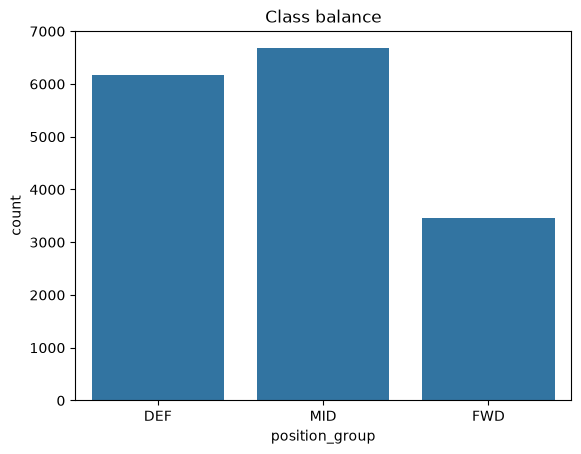

In [8]:
order = ["DEF", "MID", "FWD"]
sns.countplot(x=df[TARGET], order=order); plt.title("Class balance"); plt.show()

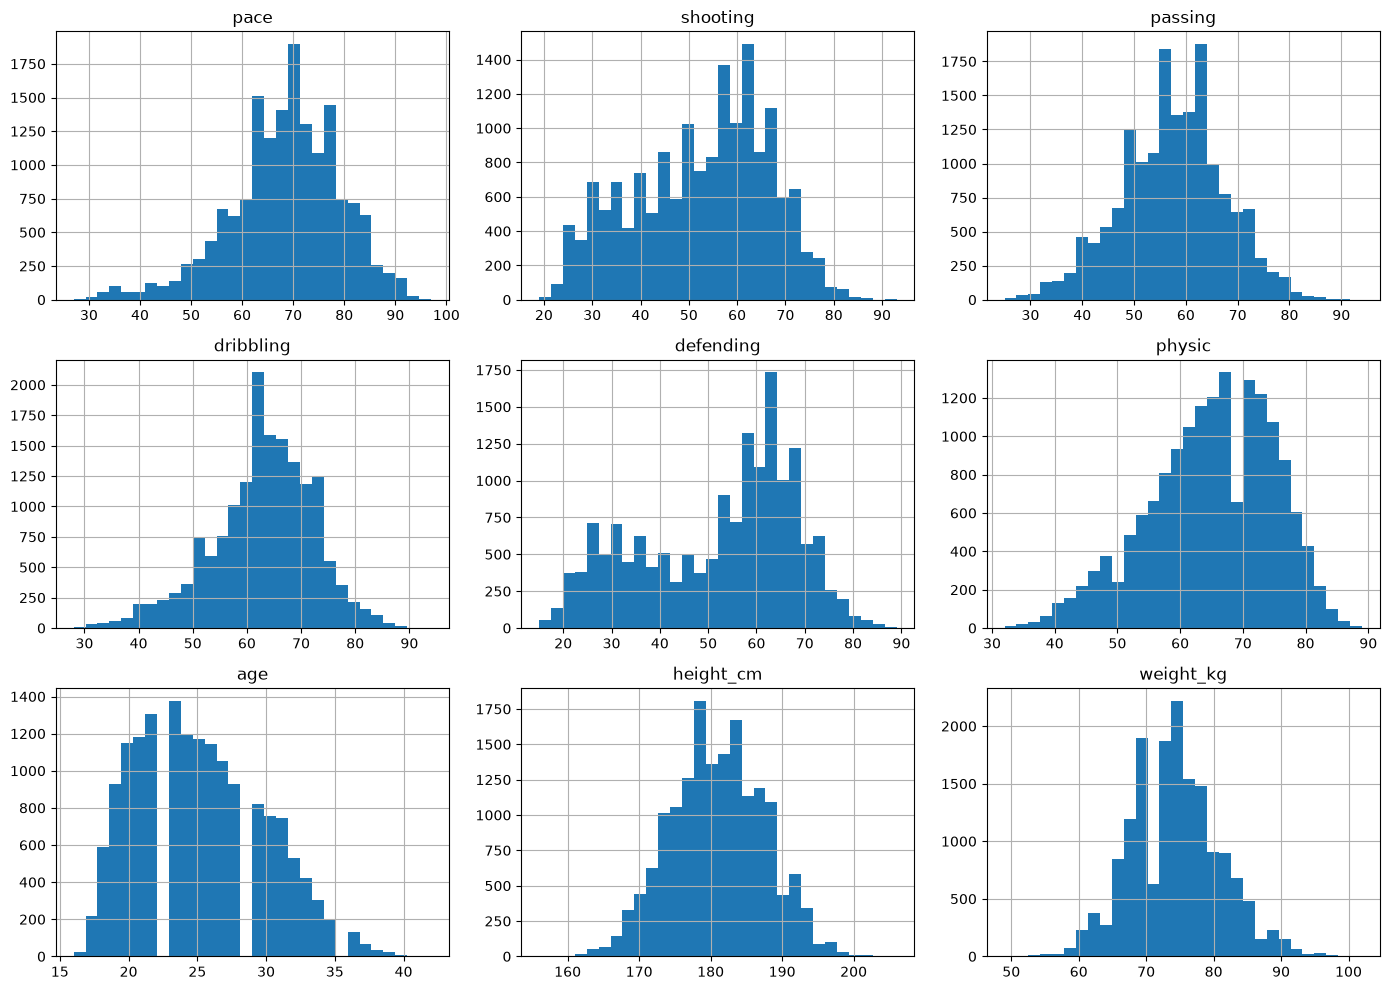

In [9]:
num_cols = df.select_dtypes(include="number").columns
main_cols = ["pace", "shooting", "passing", "dribbling", "defending", "physic", "age", "height_cm", "weight_kg"]
df[main_cols].hist(figsize=(14, 10), bins=30); plt.tight_layout(); plt.show()

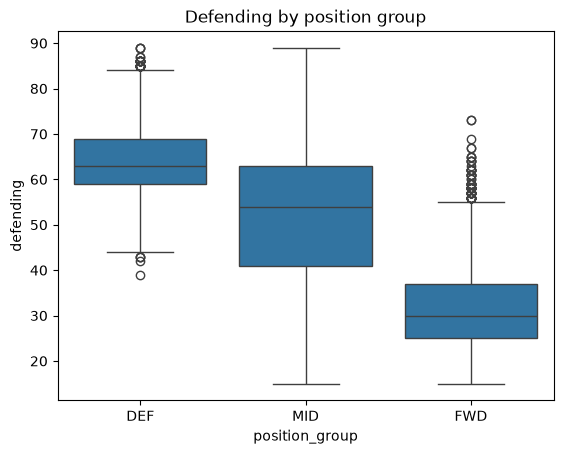

pace       outliers by IQR: 299
shooting   outliers by IQR: 0
passing    outliers by IQR: 119
dribbling  outliers by IQR: 246
defending  outliers by IQR: 0
physic     outliers by IQR: 41


In [10]:
# Box plot of one important numeric column by class: defending
sns.boxplot(x=df[TARGET], y=df["defending"], order=order); plt.title("Defending by position group"); plt.show()

# Outlier check with the IQR rule on the main stats
for c in ["pace", "shooting", "passing", "dribbling", "defending", "physic"]:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c:10s} outliers by IQR: {n_out}")

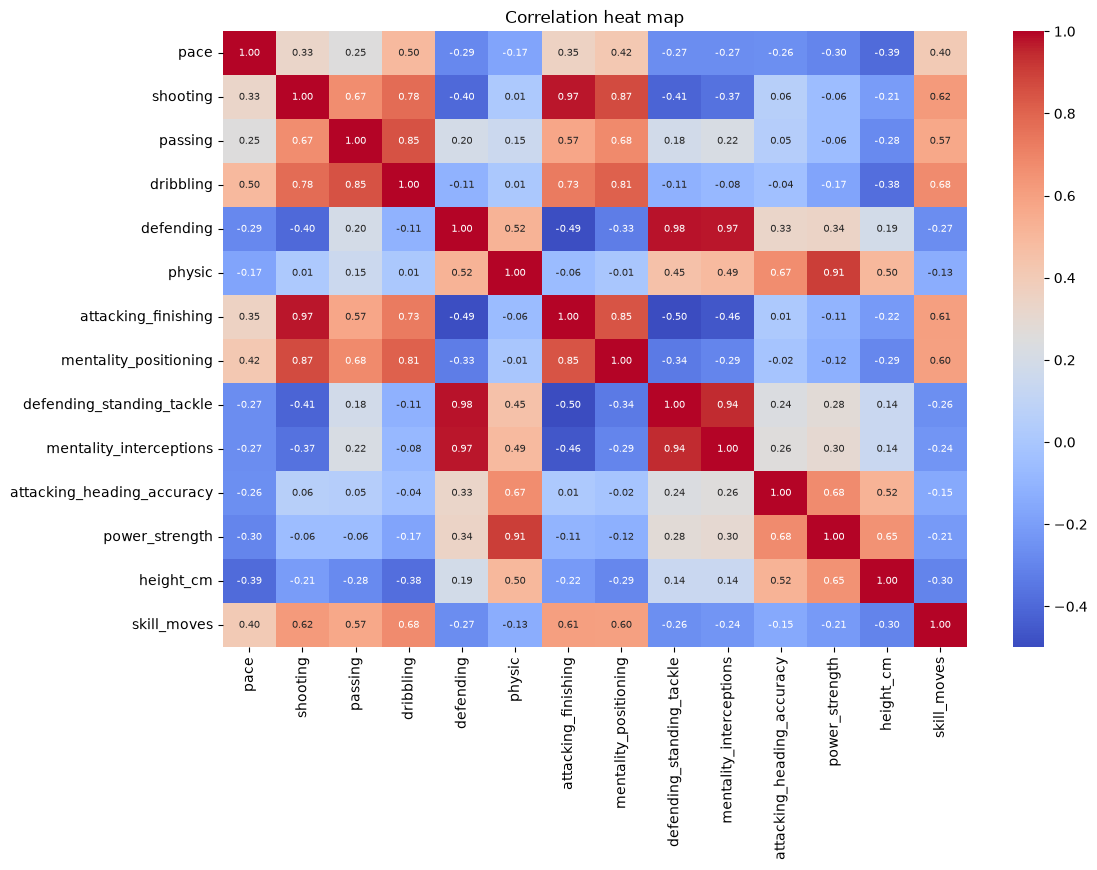

In [11]:
corr_cols = ["pace", "shooting", "passing", "dribbling", "defending", "physic", "attacking_finishing",
             "mentality_positioning", "defending_standing_tackle", "mentality_interceptions",
             "attacking_heading_accuracy", "power_strength", "height_cm", "skill_moves"]
plt.figure(figsize=(12, 8))
sns.heatmap(df[corr_cols].corr(), cmap="coolwarm", annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation heat map"); plt.show()

In [12]:
# Average of the main stats per class (numbers behind the insights)
df.groupby(TARGET)[["pace", "shooting", "passing", "dribbling", "defending", "physic",
                    "height_cm", "skill_moves"]].mean().round(1).loc[order]

,pace,shooting,passing,dribbling,defending,physic,height_cm,skill_moves
position_group,,,,,,,,
DEF,66.0,40.6,53.1,57.1,63.7,68.5,183.0,2.2
MID,68.7,57.5,62.4,66.6,51.8,62.3,178.4,2.8
FWD,72.0,64.5,55.8,65.8,32.0,63.6,181.6,2.8


✍️ **5 insights from the charts:**
1. **Defending separates the groups best:** average defending is 63.7 for DEF, 51.8 for MID and only 32.0 for FWD (box plot).
2. **Forwards shoot best:** average shooting is 64.5 for FWD, 57.5 for MID and 40.6 for DEF.
3. **Midfielders pass best:** average passing is 62.4 for MID vs 55.8 for FWD and 53.1 for DEF, and MID is in the middle on both attack and defence.
4. **Attack and defence go in opposite directions:** in the heat map, defending is negatively correlated with finishing (−0.49) and shooting (−0.40), while defending, standing tackle and interceptions are almost copies of each other (0.97–0.98), so some columns repeat the same information.
5. **Defenders are the tallest (183.0 cm on average) and physic is highest for DEF (68.5)**; pace is highest for FWD (72.0). The classes are imbalanced (count plot), and the IQR rule flags some outliers in pace (299) and dribbling (246), but they are real players (very fast or very slow), so we **keep** them.

## Step 7: Create a new feature, encode and select features

In [13]:
# 1) NEW FEATURE: how much better the player is at attacking than at defending
df["attack_defence_gap"] = (df["shooting"] + df["dribbling"]) / 2 - df["defending"]
print(df.groupby(TARGET)["attack_defence_gap"].mean().round(1).loc[order])

# 2) Separate X (inputs) and y (target)
X = df.drop(columns=[TARGET])
le_y = LabelEncoder()
y = le_y.fit_transform(df[TARGET])
print("Classes:", list(le_y.classes_))     # class 0, class 1, ...

# 3) ENCODING: turn text columns into numbers (one-hot encoding)
X = pd.get_dummies(X, drop_first=True)
print(X.shape)

position_group
DEF   -14.8
MID    10.2
FWD    33.2
Name: attack_defence_gap, dtype: float64
Classes: ['DEF', 'FWD', 'MID']
(16305, 56)


In [14]:
from sklearn.feature_selection import SelectKBest, f_classif
# 4) FEATURE SELECTION (filter method): keep the most useful columns
k = 15                            # the guide asks for SelectKBest with k = 15
selector = SelectKBest(f_classif, k=k).fit(X, y)
scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(scores.head(20).round(1))
X = X[scores.head(k).index]
feature_names = list(X.columns)
print("Selected:", feature_names)
print("Dropped by SelectKBest:", list(scores.index[k:]))

attack_defence_gap             17396.3
defending_sliding_tackle       11131.3
defending_standing_tackle       9746.3
attacking_finishing             9463.8
defending                       9307.1
defending_marking_awareness     8709.9
mentality_interceptions         8295.6
shooting                        7834.4
attacking_volleys               5363.5
power_long_shots                4972.3
mentality_penalties             4778.5
mentality_positioning           4355.2
mentality_vision                3755.8
power_shot_power                3059.9
skill_dribbling                 2586.5
dribbling                       2355.6
skill_fk_accuracy               2180.3
skill_long_passing              2025.7
skill_moves                     1961.3
passing                         1813.5
dtype: float64
Selected: ['attack_defence_gap', 'defending_sliding_tackle', 'defending_standing_tackle', 'attacking_finishing', 'defending', 'defending_marking_awareness', 'mentality_interceptions', 'shooting', 'attackin

✍️ **Write in your notebook:**
- **New feature:** `attack_defence_gap = (shooting + dribbling)/2 − defending`. It is +33.2 on average for FWD, +10.2 for MID and −14.8 for DEF, so one number tells how attacking or defensive a player is. It became the **#1 feature** in both SelectKBest (F = 17,396) and the forest's feature importance.
- **Encoding:** `get_dummies` turned `preferred_foot` and `work_rate` into 0/1 columns, giving 56 input columns.
- **SelectKBest (f_classif), k = 15** as the guide asks. **Selected (15):** attack_defence_gap, defending_sliding_tackle, defending_standing_tackle, attacking_finishing, defending, defending_marking_awareness, mentality_interceptions, shooting, attacking_volleys, power_long_shots, mentality_penalties, mentality_positioning, mentality_vision, power_shot_power, skill_dribbling.
- **Removed (41):** e.g. the 5 goalkeeping ratings, age, pace, physic, height/weight and the work-rate columns; their F-scores are much lower because they differ less between FWD, MID and DEF. Most selected columns are attacking or defending skills, which is exactly what separates the three groups.

## Step 8: Split into train and test

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print("Train class %:", (pd.Series(le_y.inverse_transform(y_train)).value_counts(normalize=True) * 100).round(1).to_dict())
print("Test class %: ", (pd.Series(le_y.inverse_transform(y_test)).value_counts(normalize=True) * 100).round(1).to_dict())

(13044, 15) (3261, 15)
Train class %: {'MID': 40.9, 'DEF': 37.9, 'FWD': 21.2}
Test class %:  {'MID': 40.9, 'DEF': 37.9, 'FWD': 21.2}


✍️ **Write in your notebook:** Train set **13,044 players × 15 features**, test set **3,261 players × 15 features** (80:20). Because of `stratify=y` both sets have the same class mix: MID 40.9%, DEF 37.9%, FWD 21.2%. **No scaling** is needed: Random Forest only asks yes/no questions like "is defending > 60?", so the units of a column do not matter.

## Step 9: Train the model: Random Forest (baseline)

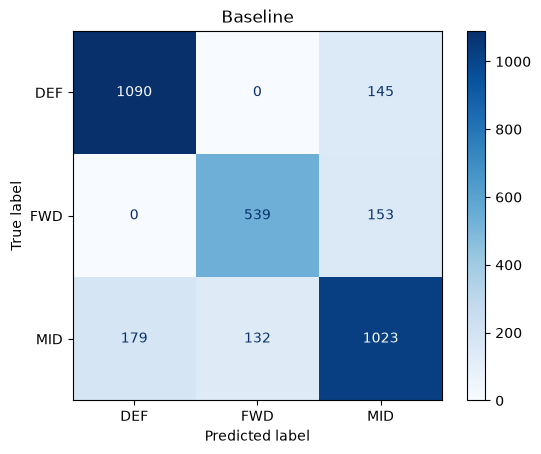

              precision    recall  f1-score   support

         DEF       0.86      0.88      0.87      1235
         FWD       0.80      0.78      0.79       692
         MID       0.77      0.77      0.77      1334

    accuracy                           0.81      3261
   macro avg       0.81      0.81      0.81      3261
weighted avg       0.81      0.81      0.81      3261

{'Setting': 'Baseline', 'Accuracy': 0.8132474701011959, 'Precision': 0.8122120207326574, 'Recall': 0.8094531313126989, 'F1': 0.8107103062701361, 'Specificity': np.float64(0.901874060931091), 'AUC': 0.9451709672757219}


In [16]:
results = []     # every setting you try is stored here

def evaluate(name, model, show=False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    spec_list = []
    for i in range(len(cm)):
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        fp = cm[:, i].sum() - cm[i, i]
        spec_list.append(tn / (tn + fp))
    spec = np.mean(spec_list)
    try:
        proba = model.predict_proba(X_test)
        auc = roc_auc_score(y_test, proba, multi_class="ovr", average="macro")
    except Exception:
        auc = None
    row = {"Setting": name,
           "Accuracy": accuracy_score(y_test, y_pred),
           "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
           "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
           "F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
           "Specificity": spec, "AUC": auc}
    if show:
        ConfusionMatrixDisplay(cm, display_labels=le_y.classes_).plot(cmap="Blues")
        plt.title(name); plt.show()
        print(classification_report(y_test, y_pred, target_names=[str(c) for c in le_y.classes_]))

    print(row)
    return row

# BASELINE: your model with default settings
model = RandomForestClassifier(random_state=42)
results.append(evaluate("Baseline", model, show=True))

In [17]:
# Confusion matrix of the baseline as numbers (rows = true class, columns = predicted class)
cm_base = confusion_matrix(y_test, model.predict(X_test))
print(pd.DataFrame(cm_base, index=["true " + c for c in le_y.classes_], columns=["pred " + c for c in le_y.classes_]))
print("Correct:", np.trace(cm_base), " Wrong:", cm_base.sum() - np.trace(cm_base), " out of", cm_base.sum())

          pred DEF  pred FWD  pred MID
true DEF      1090         0       145
true FWD         0       539       153
true MID       179       132      1023
Correct: 2652  Wrong: 609  out of 3261


✍️ **Baseline (100 trees, default settings):** accuracy **0.813**, precision 0.812, recall 0.809, **macro F1 0.811**, specificity 0.902, AUC 0.945.
**Confusion matrix in words:** out of 3,261 test players, **2,652 were correct and 609 wrong**. DEF is easiest: 1,090 of 1,235 correct, and no defender was ever called a forward (and no forward a defender). Most mistakes involve MID: 153 forwards were predicted as MID, and 179 + 132 midfielders were predicted as DEF / FWD, because midfielders are a mix of attack and defence. FWD recall is 539 of 692 = 0.78.

## Step 10: Try different settings (tuning)

{'Setting': 'n_estimators=50', 'Accuracy': 0.8101809260962894, 'Precision': 0.8081426221564176, 'Recall': 0.8078616322411447, 'F1': 0.8078935631821295, 'Specificity': np.float64(0.9005323458779309), 'AUC': 0.9427277134752204}


{'Setting': 'n_estimators=100', 'Accuracy': 0.8132474701011959, 'Precision': 0.8122120207326574, 'Recall': 0.8094531313126989, 'F1': 0.8107103062701361, 'Specificity': np.float64(0.901874060931091), 'AUC': 0.9451709672757219}


{'Setting': 'n_estimators=200', 'Accuracy': 0.8184605949095369, 'Precision': 0.8182532391232101, 'Recall': 0.8125419048450079, 'F1': 0.8152161650854156, 'Specificity': np.float64(0.9043853409564755), 'AUC': 0.9466224098585013}


{'Setting': 'max_depth=None', 'Accuracy': 0.8132474701011959, 'Precision': 0.8122120207326574, 'Recall': 0.8094531313126989, 'F1': 0.8107103062701361, 'Specificity': np.float64(0.901874060931091), 'AUC': 0.9451709672757219}


{'Setting': 'max_depth=5', 'Accuracy': 0.7816620668506593, 'Precision': 0.7778879955033419, 'Recall': 0.783813487466559, 'F1': 0.7806283081939339, 'Specificity': np.float64(0.8864346296428796), 'AUC': 0.9275682363495831}


{'Setting': 'max_depth=10', 'Accuracy': 0.8117141980987427, 'Precision': 0.8127671138395002, 'Recall': 0.8066640745293965, 'F1': 0.8095455087830707, 'Specificity': np.float64(0.9006746801936117), 'AUC': 0.9434190436257371}


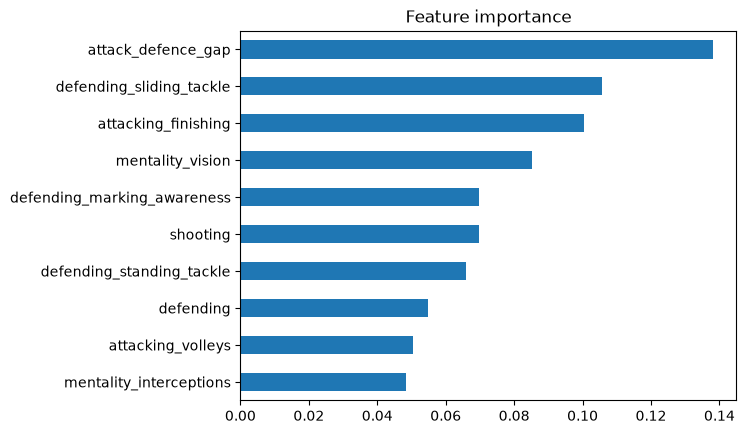

defending_marking_awareness    0.069648
mentality_vision               0.085264
attacking_finishing            0.100351
defending_sliding_tackle       0.105576
attack_defence_gap             0.138053
dtype: float64

Top 10:
 attack_defence_gap             0.138
defending_sliding_tackle       0.106
attacking_finishing            0.100
mentality_vision               0.085
defending_marking_awareness    0.070
shooting                       0.070
defending_standing_tackle      0.066
defending                      0.055
attacking_volleys              0.051
mentality_interceptions        0.048
dtype: float64


In [18]:
# A) Number of trees
for n in [50, 100, 200]:
    results.append(evaluate(f"n_estimators={n}", RandomForestClassifier(n_estimators=n, random_state=42)))

# B) max_depth
for dpt in [None, 5, 10]:
    results.append(evaluate(f"max_depth={dpt}", RandomForestClassifier(n_estimators=100, max_depth=dpt, random_state=42)))

# C) Feature importance (top 5 explain in your own words)
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
imp.tail(10).plot(kind="barh"); plt.title("Feature importance"); plt.show()
print(imp.tail(5))
print("\nTop 10:\n", imp.tail(10)[::-1].round(3))

✍️ **What changed with each setting? Which was best?**
- **n_estimators (50 → 100 → 200):** more trees gave a small, steady improvement: macro F1 0.808 → 0.811 → **0.815**, accuracy 0.810 → 0.813 → **0.818**. More trees = more votes = a steadier answer, but the gain gets smaller each time.
- **max_depth (None / 5 / 10, with 100 trees):** depth 5 was clearly worse (F1 **0.781**): trees allowed only 5 questions are too simple (underfitting). Depth 10 (0.810) was close to no limit (None, 0.811). The best is **200 trees with max_depth=None**.

**Top 5 features in plain words** (importance from the 100-tree forest):
1. **attack_defence_gap (0.138), our new feature:** attacking minus defending in one number. Big plus = forward, big minus = defender.
2. **defending_sliding_tackle (0.106):** defenders are trained to slide-tackle; forwards almost never are.
3. **attacking_finishing (0.100):** scoring from chances is the main job of a forward.
4. **mentality_vision (0.085):** seeing and playing the key pass is a midfielder's skill, so it helps pick out MID.
5. **defending_marking_awareness (0.070):** staying close to the opponent is a defender's skill.

The model decides mostly by **"how good is this player at defending vs. attacking, and can he create?"**, which is how a coach would think.

### Why is a forest of many trees more stable than one tree? (evidence)

Single trees: macro F1 from 0.710 to 0.743 (average 0.729)
Whole forest (votes of all 100 trees): macro F1 0.811


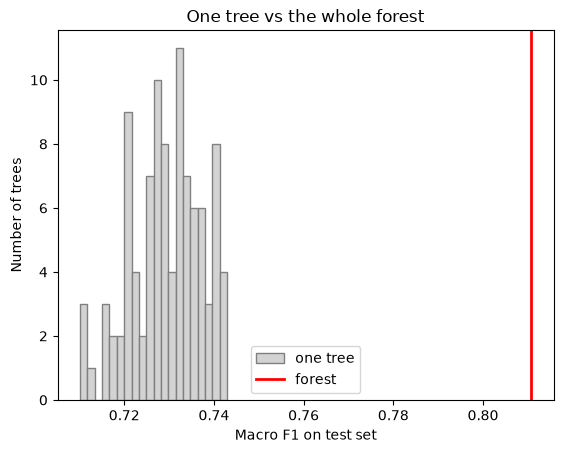

In [19]:
# Each of the 100 trees inside rf is ONE decision tree. Score every tree alone and compare with the whole forest.
tree_f1 = [f1_score(y_test, t.predict(X_test.values), average="macro") for t in rf.estimators_]
forest_f1 = f1_score(y_test, rf.predict(X_test), average="macro")
print(f"Single trees: macro F1 from {min(tree_f1):.3f} to {max(tree_f1):.3f} (average {np.mean(tree_f1):.3f})")
print(f"Whole forest (votes of all 100 trees): macro F1 {forest_f1:.3f}")
plt.hist(tree_f1, bins=20, color="lightgray", edgecolor="gray", label="one tree")
plt.axvline(forest_f1, color="red", lw=2, label="forest")
plt.xlabel("Macro F1 on test set"); plt.ylabel("Number of trees"); plt.legend()
plt.title("One tree vs the whole forest"); plt.show()

✍️ **Why is a forest more stable than one tree?** Each tree is trained on a different random sample of players (bagging) and sees a random subset of features at each split, so each tree makes *different* mistakes. Alone, one tree reached only **macro F1 0.710 to 0.743** (average 0.729); the forest's majority vote of the same 100 trees reached **0.811**. When many trees vote, their random mistakes cancel out, so the result changes much less if the data changes a little (lower variance).

## Step 11: Compare all settings and pick the final model

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline,0.813,0.812,0.809,0.811,0.902,0.945
1,n_estimators=50,0.810,0.808,0.808,0.808,0.901,0.943
2,n_estimators=100,0.813,0.812,0.809,0.811,0.902,0.945
3,n_estimators=200,0.818,0.818,0.813,0.815,0.904,0.947
4,max_depth=None,0.813,0.812,0.809,0.811,0.902,0.945
5,max_depth=5,0.782,0.778,0.784,0.781,0.886,0.928
6,max_depth=10,0.812,0.813,0.807,0.810,0.901,0.943


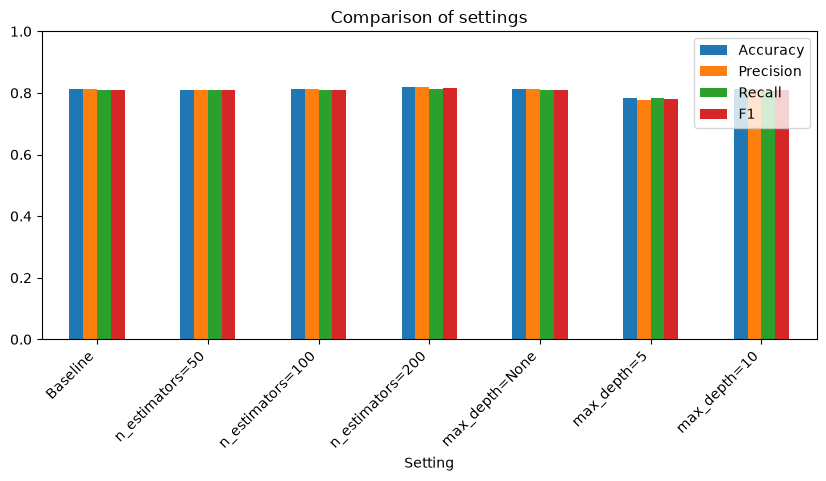

Best setting by F1: n_estimators=200
Final settings: {'n_estimators': 200}


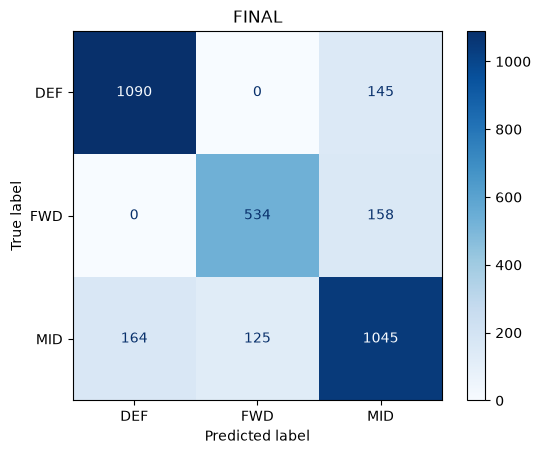

              precision    recall  f1-score   support

         DEF       0.87      0.88      0.88      1235
         FWD       0.81      0.77      0.79       692
         MID       0.78      0.78      0.78      1334

    accuracy                           0.82      3261
   macro avg       0.82      0.81      0.82      3261
weighted avg       0.82      0.82      0.82      3261

{'Setting': 'FINAL', 'Accuracy': 0.8184605949095369, 'Precision': 0.8182532391232101, 'Recall': 0.8125419048450079, 'F1': 0.8152161650854156, 'Specificity': np.float64(0.9043853409564755), 'AUC': 0.9466224098585013}


{'Setting': 'FINAL',
 'Accuracy': 0.8184605949095369,
 'Precision': 0.8182532391232101,
 'Recall': 0.8125419048450079,
 'F1': 0.8152161650854156,
 'Specificity': np.float64(0.9043853409564755),
 'AUC': 0.9466224098585013}

In [20]:
res = pd.DataFrame(results).round(3)
display(res)                                    # the comparison table for your report

res.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 4))
plt.title("Comparison of settings"); plt.ylim(0, 1); plt.xticks(rotation=45, ha="right"); plt.show()

best = res.sort_values("F1", ascending=False).iloc[0]
print("Best setting by F1:", best["Setting"])

# FINAL MODEL: the best setting, then its full result
settings = {"Baseline": {}, "n_estimators=50": {"n_estimators": 50}, "n_estimators=100": {"n_estimators": 100},
            "n_estimators=200": {"n_estimators": 200}, "max_depth=None": {"max_depth": None},
            "max_depth=5": {"max_depth": 5}, "max_depth=10": {"max_depth": 10}}
print("Final settings:", settings[best["Setting"]])
final_model = RandomForestClassifier(**settings[best["Setting"]], random_state=42)      # best setting by macro F1
evaluate("FINAL", final_model, show=True)

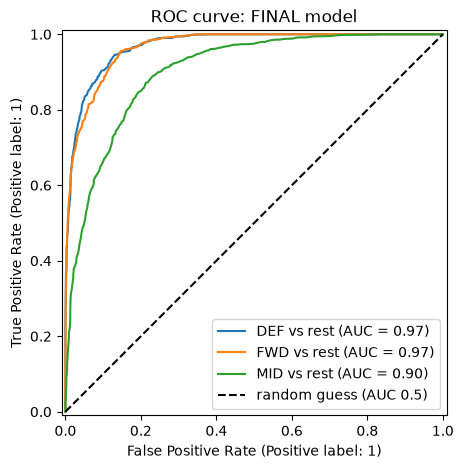

Macro AUC (OvR): 0.9466


In [21]:
# ROC curve of the final model (one class against the rest)
proba = final_model.predict_proba(X_test)
fig, ax = plt.subplots(figsize=(6, 5))
for i, cls in enumerate(le_y.classes_):
    RocCurveDisplay.from_predictions((y_test == i).astype(int), proba[:, i], name=f"{cls} vs rest", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="random guess (AUC 0.5)")
plt.title("ROC curve: FINAL model"); plt.legend(loc="lower right"); plt.show()
print("Macro AUC (OvR):", round(roc_auc_score(y_test, proba, multi_class="ovr", average="macro"), 4))

In [22]:
# Final confusion matrix in numbers, and specificity of each class
cm_final = confusion_matrix(y_test, final_model.predict(X_test))
print(pd.DataFrame(cm_final, index=["true " + c for c in le_y.classes_], columns=["pred " + c for c in le_y.classes_]))
print("Correct:", np.trace(cm_final), " Wrong:", cm_final.sum() - np.trace(cm_final), " out of", cm_final.sum())
for i, cls in enumerate(le_y.classes_):
    tp = cm_final[i, i]; fn = cm_final[i, :].sum() - tp; fp = cm_final[:, i].sum() - tp; tn = cm_final.sum() - tp - fn - fp
    print(f"{cls}: precision {tp/(tp+fp):.3f}  recall {tp/(tp+fn):.3f}  specificity {tn/(tn+fp):.3f}  (TP={tp}, FP={fp}, FN={fn}, TN={tn})")

          pred DEF  pred FWD  pred MID
true DEF      1090         0       145
true FWD         0       534       158
true MID       164       125      1045
Correct: 2669  Wrong: 592  out of 3261
DEF: precision 0.869  recall 0.883  specificity 0.919  (TP=1090, FP=164, FN=145, TN=1862)
FWD: precision 0.810  recall 0.772  specificity 0.951  (TP=534, FP=125, FN=158, TN=2444)
MID: precision 0.775  recall 0.783  specificity 0.843  (TP=1045, FP=303, FN=289, TN=1624)


✍️ **Why this final setting (3 lines):**
1. **n_estimators=200 (max_depth=None)** has the highest **macro F1 = 0.815**, and it is also best on accuracy (0.818), precision (0.818), recall (0.813), specificity (0.904) and AUC (0.947).
2. We choose by **macro F1** because the classes are imbalanced (FWD is only 21%): macro F1 gives FWD the same weight as MID and DEF, and it balances precision and recall.
3. The final model gets 2,669 of 3,261 test players right; its ROC curves are far above the diagonal (macro AUC **0.947**), so it separates the three groups well. FWD is the hardest class to find (recall 0.77) and MID has the lowest precision (0.78): most mistakes are between MID and the other two.

## Step 12: Predict 3 new inputs

In [23]:
# Start from 3 real rows and change some values to make 3 NEW realistic inputs
# (all columns, so the new feature can be recalculated; the model then uses only its 15 selected columns)
new = pd.get_dummies(df.drop(columns=[TARGET]), drop_first=True).iloc[[0, 1, 2]].copy()
profiles = {
    # Input 1: a fast, tricky WINGER (row 0 changed: more crossing, less finishing)
    0: {"pace": 92, "movement_acceleration": 94, "movement_sprint_speed": 91, "movement_agility": 90,
        "dribbling": 87, "skill_dribbling": 88, "skill_ball_control": 86, "attacking_crossing": 84,
        "shooting": 76, "attacking_finishing": 75, "attacking_volleys": 68, "power_long_shots": 74, "power_shot_power": 78,
        "mentality_positioning": 82, "mentality_penalties": 66, "passing": 78, "mentality_vision": 78,
        "defending": 35, "defending_marking_awareness": 30, "defending_standing_tackle": 33,
        "defending_sliding_tackle": 29, "mentality_interceptions": 31, "skill_moves": 4,
        "height_cm": 175, "weight_kg": 70, "physic": 66, "power_strength": 60, "attacking_heading_accuracy": 55},
    # Input 2: a PLAYMAKER in central midfield (row 1 changed: great passing and vision, average finishing)
    1: {"passing": 87, "attacking_short_passing": 89, "skill_long_passing": 86, "mentality_vision": 89, "attacking_crossing": 78,
        "skill_curve": 82, "skill_fk_accuracy": 78, "skill_ball_control": 87, "dribbling": 84, "skill_dribbling": 83,
        "shooting": 74, "attacking_finishing": 68, "attacking_volleys": 66, "power_long_shots": 80, "power_shot_power": 80,
        "mentality_positioning": 74, "mentality_penalties": 70, "pace": 70, "attacking_heading_accuracy": 55,
        "defending": 64, "defending_marking_awareness": 66, "defending_standing_tackle": 65,
        "defending_sliding_tackle": 58, "mentality_interceptions": 70, "power_stamina": 88, "skill_moves": 4,
        "movement_acceleration": 72, "movement_sprint_speed": 69, "height_cm": 178, "weight_kg": 72, "physic": 72,
        "power_strength": 68, "power_jumping": 65},
    # Input 3: a tall CENTRE-BACK (row 2 changed: strong defending and heading, weak shooting)
    2: {"defending": 85, "defending_marking_awareness": 86, "defending_standing_tackle": 87,
        "defending_sliding_tackle": 85, "mentality_interceptions": 84, "attacking_heading_accuracy": 84,
        "power_strength": 86, "power_jumping": 82, "physic": 83, "mentality_aggression": 82,
        "shooting": 42, "attacking_finishing": 35, "attacking_volleys": 34, "power_long_shots": 40,
        "power_shot_power": 60, "mentality_positioning": 38, "mentality_penalties": 40,
        "dribbling": 62, "skill_dribbling": 58, "skill_ball_control": 66, "skill_curve": 45, "skill_fk_accuracy": 38,
        "passing": 64, "attacking_short_passing": 72, "skill_long_passing": 68, "mentality_vision": 52,
        "attacking_crossing": 45, "pace": 66, "movement_agility": 60, "movement_balance": 55, "mentality_composure": 78,
        "weak_foot": 3, "skill_moves": 2, "height_cm": 191, "weight_kg": 86},
}
for row, values in profiles.items():
    for col, val in values.items():
        if col in new.columns:
            new.iloc[row, new.columns.get_loc(col)] = val
# the new feature must be recalculated from the changed values
new["attack_defence_gap"] = (new["shooting"] + new["dribbling"]) / 2 - new["defending"]
new = new[feature_names]
new.index = ["Input 1: winger", "Input 2: playmaker", "Input 3: centre-back"]
display(new)
pred = final_model.predict(new)
print("Predictions:", le_y.inverse_transform(pred))
print(pd.DataFrame(final_model.predict_proba(new).round(3), index=new.index, columns=le_y.classes_))

,attack_defence_gap,defending_sliding_tackle,defending_standing_tackle,attacking_finishing,defending,defending_marking_awareness,mentality_interceptions,shooting,attacking_volleys,power_long_shots,mentality_penalties,mentality_positioning,mentality_vision,power_shot_power,skill_dribbling
Input 1: winger,46.5,29,33,75,35.0,30,31,76.0,68,74,66,82,78,78,88
Input 2: playmaker,15.0,58,65,68,64.0,66,70,74.0,66,80,70,74,89,80,83
Input 3: centre-back,-33.0,85,87,35,85.0,86,84,42.0,34,40,40,38,52,60,58


Predictions: ['FWD' 'MID' 'DEF']
                       DEF    FWD    MID
Input 1: winger       0.00  0.725  0.275
Input 2: playmaker    0.01  0.125  0.865
Input 3: centre-back  0.99  0.000  0.010


✍️ **The 3 inputs, the predictions, and whether they make sense:**
1. **Winger** (pace 92, dribbling 87, crossing 84, finishing 75, defending 35) → **FWD** (72.5% FWD, 27.5% MID). Makes sense: wingers like LW/RW are forwards, but they also cross and create like wide midfielders, so the model is less sure.
2. **Playmaker** (passing 87, vision 89, short passing 89, defending 64, finishing 68) → **MID** (86.5%). Makes sense: great vision and passing with average finishing and average defending is a central midfielder.
3. **Centre-back** (defending 85, standing tackle 87, sliding tackle 85, interceptions 84, finishing 35) → **DEF** (99.0%). Makes sense: strong tackling with weak shooting is a classic defender.

## Step 13: Conclusion

✍️ **Conclusion:**
- **What the model can do:** from FC 24 player ratings alone, it tells whether an outfield player is a forward, midfielder or defender.
- **How good it is:** the final Random Forest (200 trees, max_depth=None, 15 features chosen by SelectKBest) gets **81.8% accuracy, macro F1 0.815, specificity 0.904 and AUC 0.947** on 3,261 unseen players. Defenders are easiest (F1 0.88); forwards are hardest to find (recall 0.77), because attacking midfielders and wingers look like forwards.
- **What I learned:** remove leaking columns first (position ratings would give a fake ~100%); one well-made feature (`attack_defence_gap`) can be the strongest of all; choose the setting with **macro F1** when classes are imbalanced; and a forest of many trees is much more stable than one tree (0.73 → 0.81 macro F1).